# Modul 11 — Model Prediksi Energi per Ton
**Tujuan teknik:** memprediksi energi per ton katoda dari kondisi proses, supaya kita bisa (a) memperkirakan konsumsi, (b) tahu variabel mana yang paling berpengaruh, (c) menaksir hemat energi bila suatu variabel digeser.

Tiga prinsip yang membedakan model yang jujur dari yang menipu:
1. **Validasi berurutan waktu**, bukan acak. Data harian berkorelasi waktu; mengacak baris membuat model "mengintip masa depan".
2. **Bandingkan dengan baseline sederhana.** Model rumit hanya layak bila mengalahkan tebakan rata-rata dan regresi linear.
3. **Hindari kebocoran data.** Energi/t = Energi ÷ Katoda, jadi Energi dan Katoda **tidak boleh** menjadi fitur.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
d = S["Data_Harian"].merge(S["Proses_Harian"], on="Tanggal"); d["Tanggal"] = pd.to_datetime(d["Tanggal"])
d = d.sort_values("Tanggal").reset_index(drop=True)
d["hari_minggu"] = d.Tanggal.dt.dayofweek
FITUR = ["Suhu_FSF_C", "O2_Enrichment_Persen", "Kelembaban_Konsentrat_Persen", "Jam_Downtime", "Cu_Grade_Persen",
         "Konsentrat_Masuk_DMT", "Matte_Grade_Persen", "Suhu_Ambien_C", "Curah_Hujan_mm", "hari_minggu"]
TARGET = "Energi_per_t_Katoda_MWh"
X, y = d[FITUR], d[TARGET]
print("Fitur:", FITUR); print("Target rata-rata %.3f, simpangan baku %.3f MWh/t" % (y.mean(), y.std()))

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx
Fitur: ['Suhu_FSF_C', 'O2_Enrichment_Persen', 'Kelembaban_Konsentrat_Persen', 'Jam_Downtime', 'Cu_Grade_Persen', 'Konsentrat_Masuk_DMT', 'Matte_Grade_Persen', 'Suhu_Ambien_C', 'Curah_Hujan_mm', 'hari_minggu']
Target rata-rata 1.470, simpangan baku 0.067 MWh/t


## 1. Model yang dibandingkan
Dua baseline (rata-rata latih; rata-rata 7 hari terakhir) dan empat model. Semua dijalankan dalam kerangka yang sama.

In [ ]:
MODEL = {
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=10, random_state=0),
}
def metrik(y_true, y_pred):
    return dict(MAE=mean_absolute_error(y_true, y_pred), RMSE=mean_squared_error(y_true, y_pred) ** .5, R2=r2_score(y_true, y_pred))

## 2. Validasi berurutan waktu (expanding window)
Lima lipatan: latih dari awal sampai titik *t*, uji pada 40 hari berikutnya, lalu perluas jendela latih. Model tidak pernah melihat data yang lebih baru daripada yang diujinya.

In [ ]:
tscv = TimeSeriesSplit(n_splits=5, test_size=40)
rows = []
for fold, (tr, te) in enumerate(tscv.split(X)):
    rows.append(dict(fold=fold, model="Baseline: rata-rata latih", **metrik(y.iloc[te], np.full(len(te), y.iloc[tr].mean()))))
    ma7 = y.rolling(7).mean().shift(1).iloc[te].fillna(y.iloc[tr].mean()).values       # rata-rata 7 hari sebelumnya
    rows.append(dict(fold=fold, model="Baseline: rata-rata 7 hari", **metrik(y.iloc[te], ma7)))
    for nama, m in MODEL.items():
        m.fit(X.iloc[tr], y.iloc[tr]); rows.append(dict(fold=fold, model=nama, **metrik(y.iloc[te], m.predict(X.iloc[te]))))
cv = pd.DataFrame(rows)
rangkum = cv.groupby("model")[["MAE", "RMSE", "R2"]].mean().sort_values("RMSE")
print(f"Latih awal {len(list(tscv.split(X))[0][0])} hari; tiap lipatan uji 40 hari. Rata-rata 5 lipatan:"); print(rangkum.round(4))

Latih awal 73 hari; tiap lipatan uji 40 hari. Rata-rata 5 lipatan:
                               MAE    RMSE      R2
model                                             
Ridge (alpha=10)            0.0267  0.0333  0.7213
Linear                      0.0267  0.0334  0.7172
Random Forest               0.0316  0.0425  0.5861
Gradient Boosting           0.0345  0.0446  0.5332
Baseline: rata-rata latih   0.0547  0.0670 -0.0222
Baseline: rata-rata 7 hari  0.0603  0.0736 -0.2439


**Cara membaca:** R² mendekati 0 (atau negatif) berarti model tidak lebih baik daripada menebak rata-rata. Jika model rumit (Random Forest, Boosting) tidak mengalahkan regresi linear, pakai yang linear: lebih sederhana, lebih mudah dijelaskan, dan sama akuratnya. Data proses fisik sering berhubungan hampir linear pada rentang operasi normal.

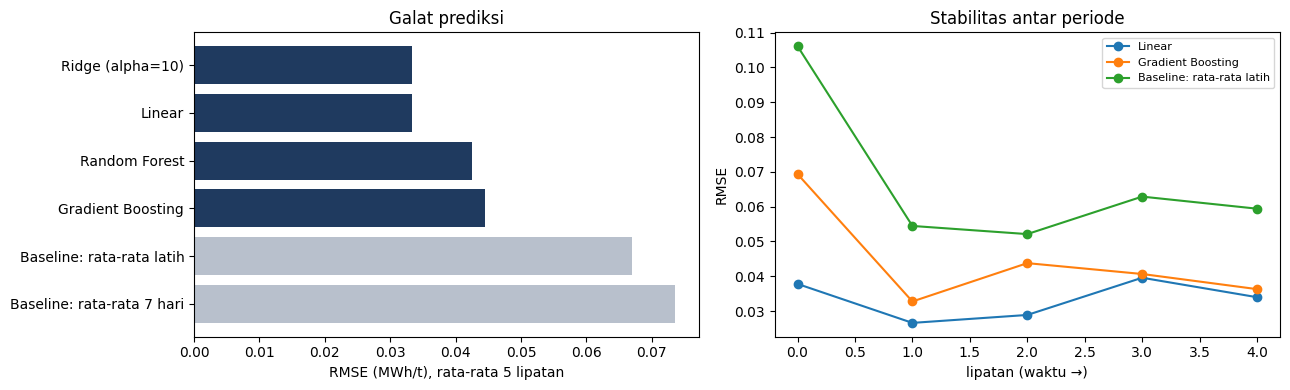

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
urut = rangkum.index.tolist()
ax[0].barh(urut[::-1], rangkum.RMSE.values[::-1], color=["#1F3A5F" if "Baseline" not in n else "#B8C0CC" for n in urut[::-1]]); ax[0].set_xlabel("RMSE (MWh/t), rata-rata 5 lipatan"); ax[0].set_title("Galat prediksi")
for n in ["Linear", "Gradient Boosting", "Baseline: rata-rata latih"]:
    s = cv[cv.model == n]; ax[1].plot(s.fold, s.RMSE, "o-", label=n)
ax[1].set_xlabel("lipatan (waktu →)"); ax[1].set_ylabel("RMSE"); ax[1].legend(fontsize=8); ax[1].set_title("Stabilitas antar periode")
plt.tight_layout(); plt.show()

## 3. Variabel mana yang penting? — permutasi pada data uji
**Permutation importance:** acak satu fitur pada data *uji*, ukur seberapa besar galat naik. Fitur yang benar-benar dipakai model akan membuat galat melonjak. Kita pakai 20% data terakhir (hold-out) dan ulangi 30 kali.

In [ ]:
n_te = int(len(X) * .2); tr_idx, te_idx = np.arange(len(X) - n_te), np.arange(len(X) - n_te, len(X))
imp = {}
for nama in ["Linear", "Gradient Boosting"]:
    m = MODEL[nama].fit(X.iloc[tr_idx], y.iloc[tr_idx])
    pi = permutation_importance(m, X.iloc[te_idx], y.iloc[te_idx], n_repeats=30, random_state=0, scoring="neg_root_mean_squared_error")
    imp[nama] = pd.Series(pi.importances_mean, index=FITUR)
imp = pd.DataFrame(imp).sort_values("Linear", ascending=False)
print("Kenaikan RMSE (MWh/t) saat fitur diacak; makin besar makin penting:"); print(imp.round(4))
print(f"\nHold-out: {n_te} hari terakhir. R² Linear = {r2_score(y.iloc[te_idx], MODEL['Linear'].predict(X.iloc[te_idx])):.3f}")

Kenaikan RMSE (MWh/t) saat fitur diacak; makin besar makin penting:
                              Linear  Gradient Boosting
Suhu_FSF_C                    0.0206             0.0233
O2_Enrichment_Persen          0.0136             0.0132
Jam_Downtime                  0.0084             0.0017
Konsentrat_Masuk_DMT          0.0010             0.0016
Matte_Grade_Persen            0.0008            -0.0004
Cu_Grade_Persen               0.0008            -0.0000
Kelembaban_Konsentrat_Persen  0.0002             0.0010
Curah_Hujan_mm               -0.0001             0.0004
hari_minggu                  -0.0001            -0.0001
Suhu_Ambien_C                -0.0003            -0.0005

Hold-out: 54 hari terakhir. R² Linear = 0.632


## 4. Bentuk hubungan: apakah linear memadai?
**Partial dependence manual:** variasikan satu fitur pada rentangnya sambil menetapkan fitur lain pada nilai aslinya, rata-ratakan prediksinya. Jika kurva Gradient Boosting hampir lurus, hubungan linear memadai.

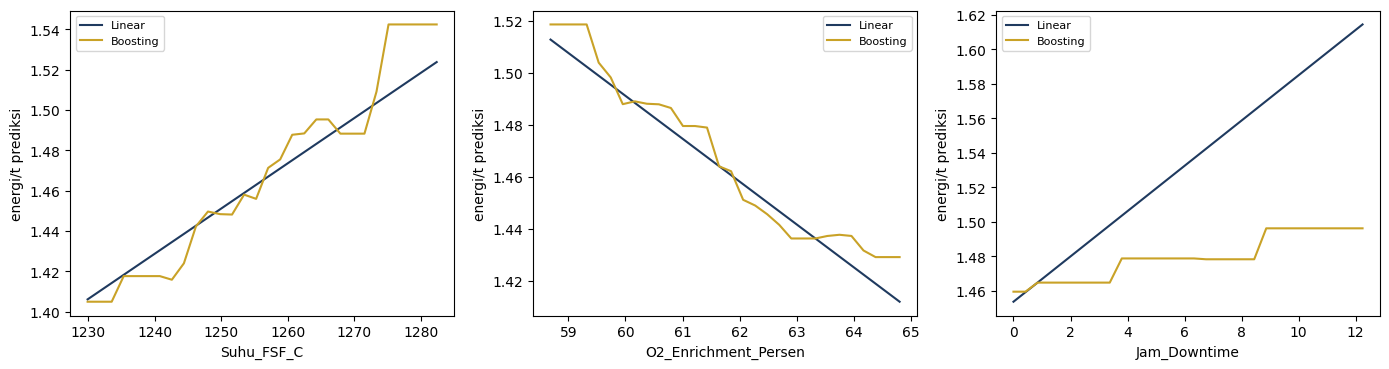

In [ ]:
def pdp(model, fitur, grid):
    out = []
    for v in grid:
        Z = X.iloc[te_idx].copy(); Z[fitur] = v; out.append(model.predict(Z).mean())
    return np.array(out)
mL = MODEL["Linear"].fit(X.iloc[tr_idx], y.iloc[tr_idx]); mG = MODEL["Gradient Boosting"].fit(X.iloc[tr_idx], y.iloc[tr_idx])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, f in zip(ax, ["Suhu_FSF_C", "O2_Enrichment_Persen", "Jam_Downtime"]):
    g = np.linspace(X[f].quantile(.02), X[f].quantile(.98), 30)
    a.plot(g, pdp(mL, f, g), label="Linear", color="#1F3A5F"); a.plot(g, pdp(mG, f, g), label="Boosting", color="#C9A227"); a.set_xlabel(f); a.set_ylabel("energi/t prediksi"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Interval prediksi (split conformal)
Prediksi titik tidak cukup untuk keputusan operasional; kita butuh rentang. **Conformal** memakai galat nyata pada data kalibrasi: ambil kuantil ke-90 galat absolut, tambahkan ±kuantil itu ke prediksi. Pembagian: 60% latih, 20% kalibrasi, 20% uji (berurutan waktu). Targetnya cakupan ≈ 90%.

Setengah lebar interval 90% = ±0.069 MWh/t | cakupan aktual pada 55 hari uji = 95%


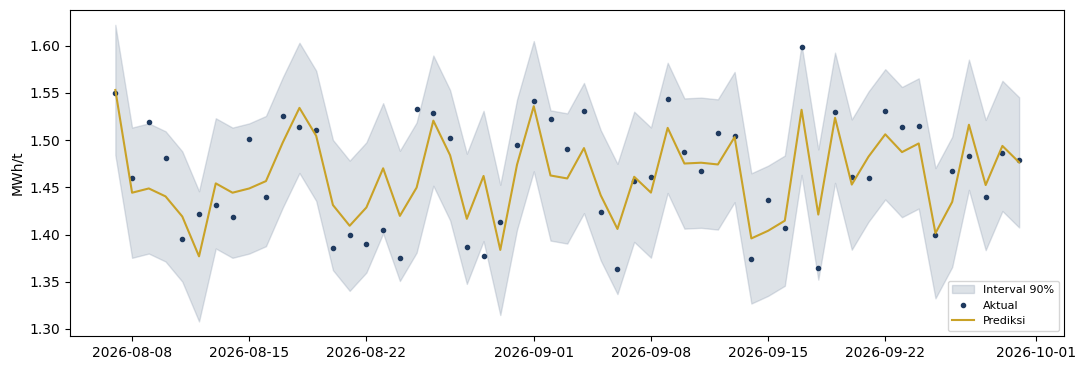

In [ ]:
n = len(X); a, b = int(n * .6), int(n * .8)
m = MODEL["Linear"].fit(X.iloc[:a], y.iloc[:a])
resid_cal = np.abs(y.iloc[a:b] - m.predict(X.iloc[a:b])); q = np.quantile(resid_cal, np.ceil((len(resid_cal) + 1) * .9) / len(resid_cal))
pred = m.predict(X.iloc[b:]); cover = ((y.iloc[b:] >= pred - q) & (y.iloc[b:] <= pred + q)).mean()
print(f"Setengah lebar interval 90% = ±{q:.3f} MWh/t | cakupan aktual pada {n-b} hari uji = {cover*100:.0f}%")
fig, ax = plt.subplots(figsize=(11, 3.8)); t = d.Tanggal.iloc[b:]
ax.fill_between(t, pred - q, pred + q, alpha=.25, color="#7A8CA3", label="Interval 90%"); ax.plot(t, y.iloc[b:], ".", color="#1F3A5F", label="Aktual"); ax.plot(t, pred, color="#C9A227", label="Prediksi")
ax.set_ylabel("MWh/t"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. What-if: berapa hemat energi bila suhu/O₂ digeser?
Dengan model linear, efek menggeser satu variabel = koefisiennya × perubahan. Ketidakpastian koefisien diukur dengan **bootstrap** (1.000 kali). Nilai dikonversi ke MWh per tahun dengan produksi rata-rata dan ke USD dengan tarif listrik rata-rata.
**Peringatan penting:** ini asosiasi di data observasi. Menurunkan suhu FSF 10 °C atau menaikkan O₂ 1 poin di lapangan bisa berdampak pada hal lain (mutu matte, umur refraktori). Gunakan sebagai *hipotesis uji coba*, bukan jaminan.

In [ ]:
rng = np.random.default_rng(11); koef = []
for _ in range(1000):
    ix = rng.integers(0, len(X), len(X)); lr = LinearRegression().fit(X.iloc[ix], y.iloc[ix]); koef.append(lr.coef_)
koef = pd.DataFrame(koef, columns=FITUR)
prod_th = d.Katoda_Cu_t.sum() / len(d) * 365; tarif = S["Harga_Biaya"].Tarif_Listrik_USD_per_MWh.mean()
skenario = {"Suhu FSF turun 10 °C": ("Suhu_FSF_C", -10), "O2 naik 1 poin": ("O2_Enrichment_Persen", +1), "Jam downtime turun 1 jam/hari": ("Jam_Downtime", -1)}
rows = []
for nama, (f, dv) in skenario.items():
    dE = koef[f] * dv                                       # MWh/t berubah
    mwh = dE * prod_th * -1                                  # hemat (positif = menghemat)
    rows.append(dict(skenario=nama, hemat_MWh_per_t=-dE.mean(), hemat_MWh_tahun=mwh.mean(), P5=np.percentile(mwh, 5), P95=np.percentile(mwh, 95), juta_USD=mwh.mean() * tarif / 1e6))
print(f"Produksi tahunan ≈ {prod_th:,.0f} t | tarif listrik rata-rata {tarif:.1f} USD/MWh")
print(pd.DataFrame(rows).round(3).to_string(index=False))

Produksi tahunan ≈ 209,008 t | tarif listrik rata-rata 73.0 USD/MWh
                     skenario  hemat_MWh_per_t  hemat_MWh_tahun       P5      P95  juta_USD
         Suhu FSF turun 10 °C            0.024         5002.776 4393.956 5615.347     0.365
               O2 naik 1 poin            0.016         3385.543 2903.089 3885.943     0.247
Jam downtime turun 1 jam/hari            0.009         1959.328  689.694 3205.489     0.143


**Kesimpulan modul 11.**
*   Ridge dan regresi linear paling baik (RMSE 0,033; R² 0,72 pada validasi walk-forward), mengungguli Random Forest dan Gradient Boosting. Hold-out R² 0,63, dan interval 90% (±0,069) mencakup 95% hari uji.
*   Variabel terpenting: suhu FSF, O2 enrichment, jam downtime.
*   What-if: suhu −10 °C menghemat 5.003 MWh/tahun, O2 +1 poin menghemat 3.386 MWh. Ini asosiasi dan perlu uji lapangan.